# MicroCT step 1a — geometry, dark, flat

Writes everything into `codedHolo.h5` **except** the frame data, which is
[`step1b_preprocess.ipynb`](step1b_preprocess.ipynb)'s job.

No rotation, no `theta` -- the scan axis is FRAMES (scan 94, 121 of them,
weak CA + strong CA + the sample, strong CA moving and the sample fixed).

Dark (scan 90) and flat (scan 91, no CA at all) are the same as this folder's
`step0a_convert` and are processed identically -- stages 0 and 1 MUST agree,
or stage 0's `code.npy`/`prb.npy` would be fitted on data normalised
differently from what step 6 reads.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../../src'))
import numpy as np, cupy as cp, h5py
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def cbshow(ax, img, title, cmap='gray', **kw):
    im = ax.imshow(np.asarray(img), cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.05)
    ax.figure.colorbar(im, cax=cax)

print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Config

In [2]:
# --- everything comes from config_step6.conf. Edit THAT file, not this cell.
from holotomocupy.config import parse_args_holo_coded
CFG = parse_args_holo_coded('config_step6.conf')

RAW_DIR = '/data3/cekmekci/microCT_nano_holo'   # raw_dir; parse_args_holo_coded has no key for it
OUT_H5  = CFG.in_file

DARK_H5   = f'{RAW_DIR}/scan-0090_orca.h5'   # dark
FLAT_H5   = f'{RAW_DIR}/scan-0091_orca.h5'   # flat: NO CA at all
WEAKCA_H5 = f'{RAW_DIR}/scan-0092_orca.h5'   # weak CA alone, no sample -> pref
GRID_H5   = f'{RAW_DIR}/scan-0094_orca.h5'   # weak + strong CA + SAMPLE (fixed), 121 frames
ORCA      = '/entry/instrument/orca/data'

ENERGY  = CFG.energy if CFG.energy is not None else 19.90
Z1      = CFG.z1                 # focus -> SAMPLE (TODO CONFIRM, see config comment)
Z_CODE  = CFG.z1_code            # focus -> weak/strong CA plane
Z_DET   = CFG.focusdetectordistance
DET_PIX = CFG.detector_pixelsize # UNBINNED
nz, n   = CFG.crop_nz, CFG.crop_n   # NATIVE crop resolution -- NOT CFG.nz/CFG.n,
                                    # which are the solve's own BINNED grid.
                                    # Steps 1a-1c never bin anything; that is
                                    # HoloCodedReader's job alone at solve time.
CROP = (nz, n)
DEZINGER = (3, 0.8)
NFRAMES = CFG.nframes   # ALL 121 frames of scan 94 -- no subsampling anywhere

print(f'{ENERGY} keV   z1(sample) {Z1} m   z1_code(CA plane) {Z_CODE} m   z_det {Z_DET} m')
print(f'crop {CROP}, native resolution -- the solve bins to {CFG.nz} x {CFG.n} at bin={CFG.bin}')
assert Z_CODE < Z1, 'the CA plane must be BEFORE the sample for RecHoloCoded'

19.9 keV   z1(sample) 0.14925 m   z1_code(CA plane) 0.14125 m   z_det 0.74625 m
crop (2048, 2048), native resolution -- the solve bins to 512 x 512 at bin=2


## Preprocessing helpers

In [3]:
# Ports of phascade.preprocess.{dark_subtract_clip, fill_dead, remove_outliers,
# flat_field_divide}. Identical to this folder's own step0a_convert -- same
# detector, same chain. Stages 0 and 1 MUST preprocess the same way, or the
# warm start from stage 0 does not line up with the data here.
from cupyx.scipy.ndimage import median_filter

def dark_subtract_clip(data, dark_mean):
    out = np.asarray(data, 'float32') - dark_mean[np.newaxis]
    np.clip(out, 0, None, out=out)
    return out

def _runs(idx):
    return [] if len(idx) == 0 else np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)

def fill_dead(data, mask):
    out = np.array(data, copy=True)
    ny, nx = mask.shape
    for g in _runs(np.where(mask.mean(1) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < ny
        for r in g:
            if hl and hh:
                w = (r - lo) / (hi - lo)
                out[..., r, :] = (1 - w) * out[..., lo, :] + w * out[..., hi, :]
            elif hl:
                out[..., r, :] = out[..., lo, :]
            elif hh:
                out[..., r, :] = out[..., hi, :]
    for g in _runs(np.where(mask.mean(0) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < nx
        for c in g:
            if hl and hh:
                w = (c - lo) / (hi - lo)
                out[..., :, c] = (1 - w) * out[..., :, lo] + w * out[..., :, hi]
            elif hl:
                out[..., :, c] = out[..., :, lo]
            elif hh:
                out[..., :, c] = out[..., :, hi]
    return out

def remove_outliers(data, radius=3, threshold=0.8):
    # window is radius x radius, NOT 2*radius+1 -- matches phascade
    res = np.asarray(data, 'float32').copy()
    for k in range(res.shape[0]):
        f = cp.asarray(res[k])
        med = median_filter(f, [radius, radius])
        res[k] = cp.asnumpy(cp.where(cp.abs(f - med) > med * threshold, med, f))
    return res

def flat_field_divide(frames, flat_mean):
    fmean = float(np.asarray(flat_mean).mean()) + 1e-12
    return np.nan_to_num(np.asarray(frames, 'float32') / fmean, nan=1.0)

def bin2(a, nbin):
    for _ in range(nbin):
        a = 0.5 * (a[..., 0::2, :] + a[..., 1::2, :])
        a = 0.5 * (a[..., :, 0::2] + a[..., :, 1::2])
    return a

## Geometry

In [4]:
with h5py.File(GRID_H5, 'r') as f:
    NANG, NY, NX = f[ORCA].shape
assert NANG == NFRAMES, f'{GRID_H5} has {NANG} frames, config says nframes={NFRAMES}'
cy, cx = NY // 2, NX // 2
SL = (slice(cy - CROP[0] // 2, cy + CROP[0] // 2),
      slice(cx - CROP[1] // 2, cx + CROP[1] // 2))

mag       = Z_DET / Z1
voxelsize = DET_PIX / mag   # NATIVE voxel size -- no bin factor, steps 1a-1c never bin

print(f'orca {NY} x {NX}, {NANG} frames; crop rows {SL[0].start}:{SL[0].stop} '
      f'cols {SL[1].start}:{SL[1].stop}')
print(f'voxel {voxelsize*1e9:.2f} nm   magnification {mag:.3f}')

orca 2592 x 4608, 121 frames; crop rows 272:2320 cols 1280:3328
voxel 46.00 nm   magnification 5.000


## Dark, flat, dead-pixel mask

Written into `codedHolo.h5` so step1b/step1c read them back -- one file, no
sidecar, same as `AtomiumS2_coded/step1` and `BoneNano_coded_holotomo/step1`.

dead threshold 710.2 ADU   dead pixels 0
  dead rows []
  dead cols []
flat_mean 14196.0 ADU -> /exchange/{dark,flat_norm,dead_mask,flat_mean}


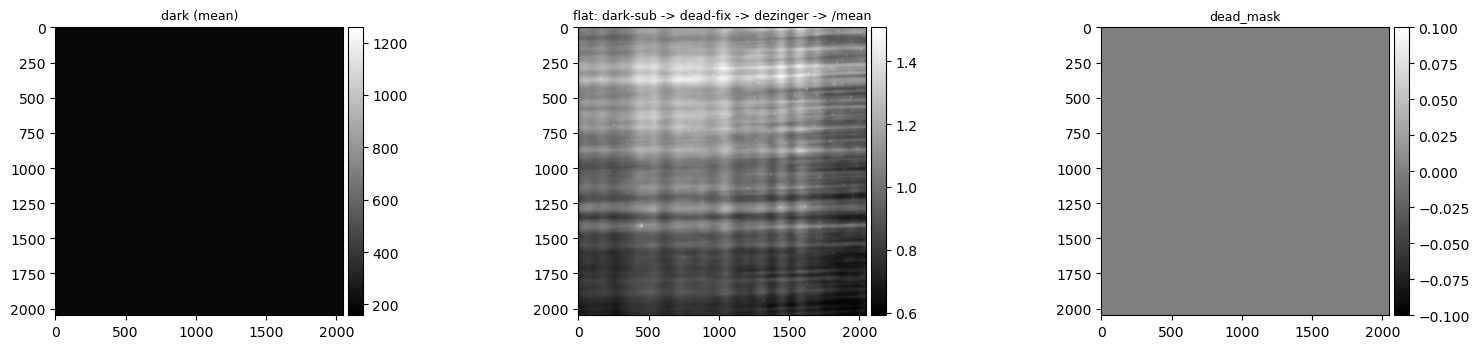

In [5]:
def _mean_stack(path, sl):
    with h5py.File(path, 'r') as f:
        d = f[ORCA]
        acc = np.zeros((sl[0].stop - sl[0].start, sl[1].stop - sl[1].start), 'float64')
        for i in range(d.shape[0]):
            acc += d[i, sl[0], sl[1]]
        return (acc / d.shape[0]).astype('float32')

dark = _mean_stack(DARK_H5, SL)
flat = dark_subtract_clip(_mean_stack(FLAT_H5, SL)[None], dark)[0]

thr = 0.05 * np.median(flat[flat > 0])
dead_mask = flat < thr
print(f'dead threshold {thr:.1f} ADU   dead pixels {int(dead_mask.sum())}')
print('  dead rows', np.where(dead_mask.mean(1) > 0.5)[0].tolist())
print('  dead cols', np.where(dead_mask.mean(0) > 0.5)[0].tolist())

flat = fill_dead(flat[None], dead_mask)[0]
flat = remove_outliers(flat[None], 3, 0.8)[0]
flat_mean = float(flat.mean())
flat_norm = (flat / flat_mean).astype('float32')

os.makedirs(os.path.dirname(OUT_H5), exist_ok=True)
with h5py.File(OUT_H5, 'a') as f:
    for k, v in (('dark', dark), ('flat_norm', flat_norm),
                 ('dead_mask', dead_mask.astype('uint8'))):
        if f'/exchange/{k}' in f:
            del f[f'/exchange/{k}']
        f.create_dataset(f'/exchange/{k}', data=v)
    if '/exchange/flat_mean' in f:
        del f['/exchange/flat_mean']
    f.create_dataset('/exchange/flat_mean', data=np.array([flat_mean], 'float64'))
print(f'flat_mean {flat_mean:.1f} ADU -> /exchange/{{dark,flat_norm,dead_mask,flat_mean}}')

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
cbshow(ax[0], dark, 'dark (mean)')
cbshow(ax[1], flat_norm, 'flat: dark-sub -> dead-fix -> dezinger -> /mean')
cbshow(ax[2], dead_mask.astype('float32'), 'dead_mask')
plt.tight_layout(); plt.show()

## Write geometry

In [6]:
with h5py.File(OUT_H5, 'a') as f:
    for k, v in (('energy', ENERGY), ('z1', Z1),
                 ('focusdetectordistance', Z_DET),
                 ('detector_pixelsize', DET_PIX),          # UNBINNED
                 ('voxelsize', voxelsize)):
        if f'/exchange/{k}' in f:
            del f[f'/exchange/{k}']
        f.create_dataset(f'/exchange/{k}', data=np.array([v], 'float64'))
print('wrote geometry ->', OUT_H5)
print('NOTE detector_pixelsize is written UNBINNED; HoloCodedReader scales it by 2**bin.')
print('Next: step1b_preprocess.ipynb')

wrote geometry -> /data3/cekmekci/MicroCT_coded_holo/holo/codedHolo.h5
NOTE detector_pixelsize is written UNBINNED; HoloCodedReader scales it by 2**bin.
Next: step1b_preprocess.ipynb
